# **UTS Graf Sains Data - Analisis Sistem Rekomendasi Retail Rocket**
Bilqis Fadiyah Nisrina (24031554216)

---   

## **BAGIAN 1: PEMAHAMAN DASAR NEO4J & CYPHER QUERY**
### **Soal 1.1: Koneksi Python Driver ke Database Neo4j**
Menghubungkan Jupyter Notebook dengan instance Neo4j lokal (`bolt://localhost:7687`) menggunakan kredensial `neo4j` dan kata sandi `bilqis216`.

In [13]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "bilqis216")


def add_friend(driver, name, friend_name):
  driver.execute_query(
      "MERGE (a:Person {name: $name}) "
      "MERGE (friend:Person {name: $friend_name}) "
      "MERGE (a)-[:KNOWS]->(friend)",
      name=name, friend_name=friend_name, database_="neo4j",
  )


def print_friends(driver, name):
  records, _, _ = driver.execute_query(
      "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
      "RETURN friend.name ORDER BY friend.name",
      name=name, database_="neo4j", routing_=RoutingControl.READ,
  )
  for record in records:
    print(f"- {record['friend.name']}")


with GraphDatabase.driver(URI, auth=AUTH) as driver:
  add_friend(driver, "Arthur", "Guinevere")
  add_friend(driver, "Arthur", "Lancelot")
  add_friend(driver, "Arthur", "Merlin")
  print_friends(driver, "Arthur")

- Guinevere
- Lancelot
- Merlin


### **Jawaban Pertanyaan Soal 1.2 (Berdasarkan Eksekusi Kode)**
1. **Nama Database yang Digunakan:** Database default yang aktif adalah `neo4j`[cite: 4].
2. **Akses Lain (Sintaks DDL/DML CYPHER) dalam 1 Instance:**
   - `SHOW DATABASES` : Melihat daftar seluruh database[cite: 4].
   - `CREATE DATABASE nama_db` : Membuat database baru[cite: 4].
   - `DROP DATABASE nama_db` : Menghapus database tertentu[cite: 4].
   - `USE nama_db` : Menentukan database target[cite: 4].
3. **Jenis Graf Pertemanan:** Directed Graph (Graf Berarah) karena relasi `(:Person)-[:KNOWS]->(:Person)` hanya berarah satu jalur[cite: 4].


---
## **BAGIAN 2: PERSIAPAN DATASET RETAIL ROCKET & TRUNCATE DATABASE**
Dibersihkan secara bertahap (batch size 10.000) agar memori aman[cite: 4], lalu dataset `events.csv` dipisah jadi P1 (Train) dan P2 (Test).

In [14]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "bilqis216")

query_truncate = """
MATCH (n)
CALL {
    WITH n
    DETACH DELETE n
} IN TRANSACTIONS OF 10000 ROWS
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
  with driver.session(database="neo4j") as session:
    session.run(query_truncate)
    print("Database berhasil dibersihkan secara aman!")

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=3, column=1, offset=11>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 11, 'line': 3, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (n)\nCALL {\n    WITH n\n    DETACH DELETE n\n} IN TRANSACTIONS OF 10000 ROWS\n'


Database berhasil dibersihkan secara aman!


In [15]:
# Filtering & Export Data P1 dan P2
import numpy as np
import pandas as pd

# Load dataset events.csv
df_events = pd.read_csv('events.csv')

# Konversi timestamp epoch ke datetime
df_events['datetime'] = pd.to_datetime(df_events['timestamp'], unit='ms')

# Filter Periode P1 (Juni 2015: Train) dan P2 (1-15 Juli 2015: Test)
p1_mask = (df_events['datetime'] >= '2015-06-01') & (df_events['datetime'] < '2015-07-01')
p2_mask = (df_events['datetime'] >= '2015-07-01') & (df_events['datetime'] <= '2015-07-15')

df_p1 = df_events[p1_mask].copy()
df_p2 = df_events[p2_mask].copy()

# Export ke file CSV terpisah
df_p1.to_csv('events_p1_train.csv', index=False)
df_p2.to_csv('events_p2_test.csv', index=False)

print(f'Total Interaksi P1 (Train) : {len(df_p1):,}')
print(f'Total Interaksi P2 (Test)  : {len(df_p2):,}')

Total Interaksi P1 (Train) : 610,393
Total Interaksi P2 (Test)  : 309,637


### **Soal 2.1 No. 1 & 2: Indeks Unik dan Impor Subgraph P1 Ter-Optimasi**
Dibuat Uniqueness Constraint untuk `Visitor` dan `Item` agar pencarian cepat[cite: 5], lalu diimpor bertahap (batch 5000) pakai `UNWIND`.

In [16]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "bilqis216")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
  with driver.session(database="neo4j") as session:
    session.run(
        "CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS FOR (v:Visitor)"
        " REQUIRE v.visitorid IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT item_id_unique IF NOT EXISTS FOR (i:Item) REQUIRE"
        " i.itemid IS UNIQUE"
    )
    print("Constraint & Index berhasil dibuat!")

Constraint & Index berhasil dibuat!


In [17]:
# Impor Batch Data P1 ke Neo4j
import pandas as pd
from tqdm import tqdm

driver = GraphDatabase.driver(URI, auth=AUTH)

batch_size = 5000
chunks = pd.read_csv("events_p1_train.csv", chunksize=batch_size)

total_rows = len(pd.read_csv("events_p1_train.csv", usecols=[0]))
total_chunks = (total_rows // batch_size) + 1


def import_batch_optimized(tx, batch):
  cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionid: row.transactionid}]->(i)
    }
    """
  tx.run(cypher_query, batch=batch)


with driver.session(database="neo4j") as session:
  for chunk in tqdm(
      chunks, total=total_chunks, desc="Mengimpor P1 ke Neo4j (Optimized)"
  ):
    chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
    records = chunk.to_dict(orient="records")
    session.execute_write(import_batch_optimized, records)

print("Proses Impor P1 ke Neo4j SELESAI!")

Mengimpor P1 ke Neo4j (Optimized): 100%|██████████| 123/123 [01:48<00:00,  1.14it/s]

Proses Impor P1 ke Neo4j SELESAI!


### **Soal 2.1 No. 3: Komposisi Subgraph Periode P1**
Menghitung total node Visitor, Item, dan jumlah relasi interaksinya (VIEWED, ADDED_TO_CART, BOUGHT).

In [19]:
# Perhitungan Komposisi Subgraph P1
def hitung_komposisi(tx):
  v_count = tx.run("MATCH (v:Visitor) RETURN count(v) AS total").single()["total"]
  i_count = tx.run("MATCH (i:Item) RETURN count(i) AS total").single()["total"]
  view_count = tx.run("MATCH ()-[r:VIEWED]->() RETURN count(r) AS total").single()["total"]
  cart_count = tx.run("MATCH ()-[r:ADDED_TO_CART]->() RETURN count(r) AS total").single()["total"]
  bought_count = tx.run("MATCH ()-[r:BOUGHT]->() RETURN count(r) AS total").single()["total"]

  print("KOMPOSISI SUBGRAPH PERIODE P1")
  print(f"Total Node       : {v_count + i_count:,}")
  print(f"  - Visitor      : {v_count:,}")
  print(f"  - Item         : {i_count:,}")
  print(f"Total Relationship: {view_count + cart_count + bought_count:,}")
  print(f"  - VIEWED       : {view_count:,}")
  print(f"  - ADDED_TO_CART: {cart_count:,}")
  print(f"  - BOUGHT       : {bought_count:,}")


with driver.session(database="neo4j") as session:
  session.execute_read(hitung_komposisi)

KOMPOSISI SUBGRAPH PERIODE P1
Total Node       : 431,149
  - Visitor      : 313,832
  - Item         : 117,317
Total Relationship: 610,393
  - VIEWED       : 590,255
  - ADDED_TO_CART: 15,095
  - BOUGHT       : 5,043


### **Uraian Query Cypher untuk Komposisi Subgraph (Soal 2.1 No. 3)**
- **Node Visitor:** `MATCH (v:Visitor) RETURN count(v) AS total`
- **Node Item:** `MATCH (i:Item) RETURN count(i) AS total`[cite: 7]
- **Relationship Interaksi:**
  - `MATCH ()-[r:VIEWED]->() RETURN count(r) AS total`[cite: 7]
  - `MATCH ()-[r:ADDED_TO_CART]->() RETURN count(r) AS total`[cite: 7]
  - `MATCH ()-[r:BOUGHT]->() RETURN count(r) AS total`[cite: 7]

### **Soal 2.1 No. 4 & 5: Pembentukan Matriks VSM User dan Item**
- **VSM User:** Row = Visitor, Column = Item[cite: 7].
- **VSM Item:** Row = Item, Column = Visitor[cite: 8, 9].

VSM USER
Shape Matriks       : (313832, 117317)
Dimensi Vektor User : 117317 fitur (Items)


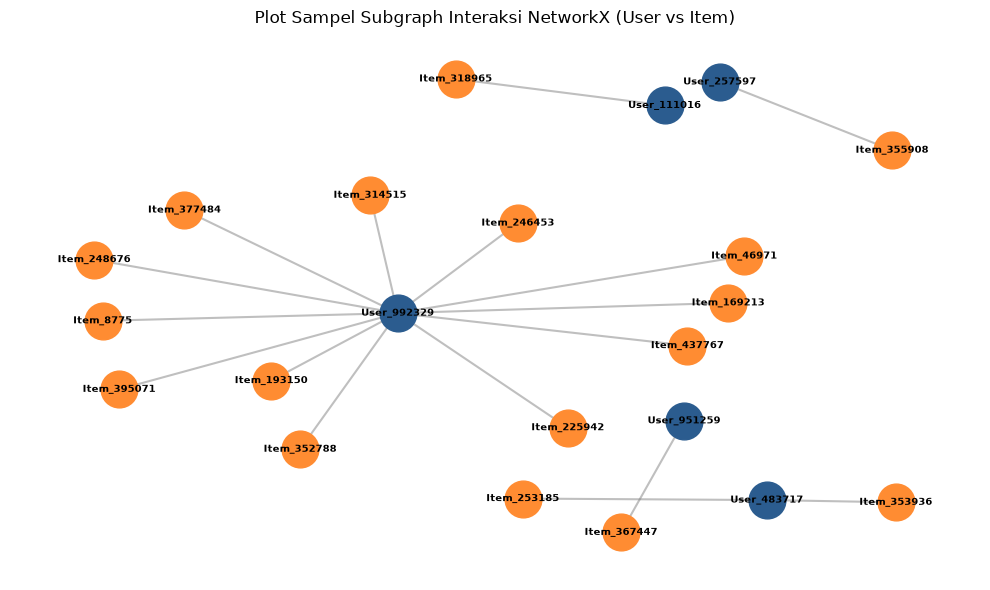

In [21]:
# VSM User & Visualisasi NetworkX
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import csr_matrix

df = pd.read_csv("events_p1_train.csv")
visitor_ids = df["visitorid"].unique()
item_ids = df["itemid"].unique()

visitor2idx = {vid: i for i, vid in enumerate(visitor_ids)}
item2idx = {iid: i for i, iid in enumerate(item_ids)}

rows = df["visitorid"].map(visitor2idx).values
cols = df["itemid"].map(item2idx).values
data = np.ones(len(df), dtype=int)

user_item_matrix = csr_matrix(
    (data, (rows, cols)), shape=(len(visitor_ids), len(item_ids))
)

print("VSM USER")
print(f"Shape Matriks       : {user_item_matrix.shape}")
print(f"Dimensi Vektor User : {user_item_matrix.shape[1]} fitur (Items)")

sample_users = visitor_ids[:5]
sample_df = df[df["visitorid"].isin(sample_users)].head(20)

B = nx.Graph()
for _, row in sample_df.iterrows():
  u_node = f"User_{row['visitorid']}"
  i_node = f"Item_{row['itemid']}"
  B.add_node(u_node, type="user")
  B.add_node(i_node, type="item")
  B.add_edge(u_node, i_node)

user_nodes = [n for n, d in B.nodes(data=True) if d["type"] == "user"]
item_nodes = [n for n, d in B.nodes(data=True) if d["type"] == "item"]

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(B, k=0.8, seed=42)

nx.draw_networkx_nodes(B, pos, nodelist=user_nodes, node_color="#2b5c8f", node_size=700)
nx.draw_networkx_nodes(B, pos, nodelist=item_nodes, node_color="#ff8c32", node_size=700)
nx.draw_networkx_edges(B, pos, alpha=0.5, edge_color="gray", width=1.5)
nx.draw_networkx_labels(B, pos, font_size=7, font_color="black", font_weight="bold")

plt.title("Plot Sampel Subgraph Interaksi NetworkX (User vs Item)", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

### **Penjelasan Visualisasi Plot Sampel Subgraph NetworkX (User vs Item)**

1. **Entitas Node (Simpul):**
   * **Node Biru (`User_...`):** Mewakili entitas *Visitor* (pengguna)[cite: 6].
   * **Node Oranye (`Item_...`):** Mewakili entitas *Item* (produk)[cite: 6].

2. **Struktur Relasi (Edge):**
   * Garis abu-abu (sisi/edge) menggambarkan **interaksi** yang terjadi antara *Visitor* dan *Item* pada dataset periode P1[cite: 6].
   * Terlihat struktur *Bipartite Graph*, di mana relasi hanya terhubung antara Node User dan Node Item (tidak ada hubungan langsung antar-User atau antar-Item)[cite: 6].

3. **Pola Pola Interaksi Pengguna:**
   * **User Aktif (Pusat Hub):** Terlihat node seperti `User_992329` memiliki derajat (*degree*) yang tinggi karena berinteraksi dengan banyak item sekaligus dalam satu periode[cite: 6].
   * **User Pasif:** Node seperti `User_257597` hanya berinteraksi dengan 1–2 item[cite: 6].
   * Pola hubungan inilah yang kemudian diproyeksikan ke dalam **Vector Space Model (VSM)** untuk mengukur kemiripan (*similarity*) antar-item maupun antar-user.

VSM ITEM
Shape Matriks       : (117317, 313832)
Dimensi Vektor Item : 313832 fitur (Users)


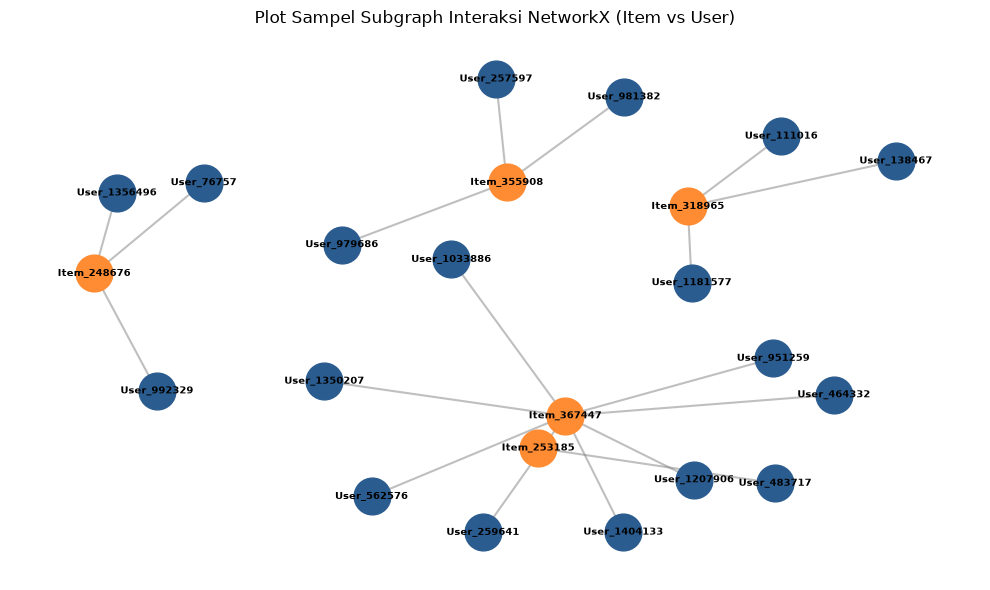

In [22]:
# VSM Item & Visualisasi NetworkX
rows = df["itemid"].map(item2idx).values
cols = df["visitorid"].map(visitor2idx).values
item_user_matrix = csr_matrix(
    (data, (rows, cols)), shape=(len(item_ids), len(visitor_ids))
)

print("VSM ITEM")
print(f"Shape Matriks       : {item_user_matrix.shape}")
print(f"Dimensi Vektor Item : {item_user_matrix.shape[1]} fitur (Users)")

sample_items = item_ids[:5]
sample_df = df[df["itemid"].isin(sample_items)].head(20)

B = nx.Graph()
for _, row in sample_df.iterrows():
  u_node = f"User_{row['visitorid']}"
  i_node = f"Item_{row['itemid']}"
  B.add_node(u_node, type="user")
  B.add_node(i_node, type="item")
  B.add_edge(u_node, i_node)

user_nodes = [n for n, d in B.nodes(data=True) if d["type"] == "user"]
item_nodes = [n for n, d in B.nodes(data=True) if d["type"] == "item"]

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(B, k=0.8, seed=42)

nx.draw_networkx_nodes(B, pos, nodelist=item_nodes, node_color="#ff8c32", node_size=700)
nx.draw_networkx_nodes(B, pos, nodelist=user_nodes, node_color="#2b5c8f", node_size=700)
nx.draw_networkx_edges(B, pos, alpha=0.5, edge_color="gray", width=1.5)
nx.draw_networkx_labels(B, pos, font_size=7, font_color="black", font_weight="bold")

plt.title("Plot Sampel Subgraph Interaksi NetworkX (Item vs User)", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

### **Penjelasan Visualisasi Plot Sampel Subgraph NetworkX (Item vs User)**

1. **Prespektif Berbasis Item (Item-Centric View):**
   * **Node Oranye (`Item_...`):** Mewakili entitas *Item* (produk) sebagai objek pusat analisis[cite: 7].
   * **Node Biru (`User_...`):** Mewakili entitas *Visitor* (pengguna) yang berinteraksi dengan produk tersebut[cite: 7].

2. **Karakteristik & Pola Hubungan:**
   * **Item Populer (Hub/Cluster):** Node seperti `Item_367447` menjadi pusat perhatian (*hub*) karena diakses dan dibeli oleh banyak *User* berbeda (`User_951259`, `User_464332`, `User_1207906`, dll.)[cite: 7].
   * **Co-Occurrence (Kemunculan Bersama):** Node `Item_367447` dan `Item_253185` saling terhubung melalui *User* yang sama (`User_1404133` & `User_259641`)[cite: 7]. Pola ini menunjukkan bahwa kedua item tersebut sering dilihat atau dibeli secara bersamaan (*frequently bought/viewed together*)[cite: 7].

3. **Relevansi dengan Vector Space Model (VSM) Item:**
   * Pada VSM Item, setiap item direpresentasikan sebagai vektor berdimensi 313,832 fitur (seluruh *Users*)[cite: 7].
   * Semakin banyak irisan *User* biru yang terhubung ke dua *Item* oranye yang berbeda, semakin tinggi nilai **Cosine Similarity** di antara kedua item tersebut[cite: 7]. Prinsip inilah yang menjadi dasar pencarian barang serupa (*similar items*) pada algoritma Item-based KNN[cite: 7].

### **Soal 2.1 No. 6: Analisis Efektivitas Proyeksi VSM**
Proyeksi **VSM Item (Item-based)** jauh lebih efektif dan efisien dibanding User-based karena:
1. **Stabilitas Data:** Atribut item bersifat statis, sedangkan perilaku visitor anonim cepat berubah[cite: 9].
2. **Efisiensi Memori:** Jumlah item (117.317) jauh lebih sedikit dari visitor (313.832) sehingga komputasi similarity lebih ringan[cite: 7, 8, 9].
3. **Sparsity:** Vektor item lebih kaya informasi (*dense*) karena mengumpulkan interaksi dari seluruh visitor[cite: 9].

In [24]:
# Cosine Similarity & Write-Back ke Neo4j
from sklearn.metrics.pairwise import cosine_similarity

sample_item_idx = 0
sample_item_id = item_ids[sample_item_idx]

sample_vector = item_user_matrix[sample_item_idx : sample_item_idx + 1]
sim_scores_vector = cosine_similarity(sample_vector, item_user_matrix).ravel()

sim_scores = list(enumerate(sim_scores_vector))
sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:6]

print(f"TOP 5 ITEM SIMILAR TO ITEM {sample_item_id} (Soal 2.1 No. 7a)")
top_similar_items = []
for idx, score in sim_scores:
  target_item_id = item_ids[idx]
  top_similar_items.append((int(target_item_id), float(score)))
  print(f"Item ID: {target_item_id} | Cosine Similarity: {score:.4f}")


def create_similarity_edges(tx, source_id, similar_list):
  query = """
    MATCH (source:Item {itemid: $source_id})
    UNWIND $similar_list AS item
    MATCH (target:Item {itemid: item.target_id})
    MERGE (source)-[r:SIMILAR_TO {score: item.score}]->(target)
    """
  formatted_list = [{"target_id": t_id, "score": score} for t_id, score in similar_list]
  tx.run(query, source_id=int(source_id), similar_list=formatted_list)


with driver.session() as session:
  session.execute_write(create_similarity_edges, sample_item_id, top_similar_items)

print("\nRelationship SIMILAR_TO berhasil dituliskan kembali ke Neo4j!")

TOP 5 ITEM SIMILAR TO ITEM 355908 (Soal 2.1 No. 7a)
Item ID: 73646 | Cosine Similarity: 0.3780
Item ID: 238777 | Cosine Similarity: 0.3479
Item ID: 227867 | Cosine Similarity: 0.3282
Item ID: 436412 | Cosine Similarity: 0.2817
Item ID: 97139 | Cosine Similarity: 0.2694

Relationship SIMILAR_TO berhasil dituliskan kembali ke Neo4j!


### **Soal 2.1 No. 8: Kueri Cypher & Visualisasi Graf Sebelum dan Sesudah Similarity**

---

#### **1. Kondisi SEBELUM Perhitungan Similarity**
```cypher
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v, r, i
LIMIT 10;

![Visualisasi Sebelum](sebelum.png)

Graf menampilkan hubungan interaksi langsung (seperti VIEWED, ADDED_TO_CART, atau BOUGHT) antara node Visitor dan node Item. Pada kondisi ini, belum terdapat relasi antar-item.

---

#### **2. Kondisi SESUDAH Perhitungan Similarity**
Kueri ini dijalankan di Neo4j Browser untuk menampilkan graf relasi SIMILAR_TO antar-Item hasil perhitungan Cosine Similarity:

```cypher
MATCH (i1:Item)-[r:SIMILAR_TO]->(i2:Item)
RETURN i1, r, i2
LIMIT 5;

![Visualisasi Sebelum](sesudah.png)

Graf menampilkan 1 node Item pusat yang terhubung langsung ke 5 node Item paling mirip di sekitarnya melalui relasi SIMILAR_TO beserta skor kemiripannya.

## **BAGIAN 4: EVALUASI SISTEM REKOMENDASI KNN (SOAL 2.2)**

### **Soal 2.2: Rekomendasi Item-based KNN (k=5) & Evaluasi Metrik**

#### **1. Penjelasan Metodologi Kueri Cypher KNN (Cosine Similarity)**
* **Pendekatan:** Menggunakan algoritma *Collaborative Filtering* berbasis Cosine Similarity langsung di dalam database graf Neo4j.
* **Mekanisme Kueri:**
  1. Mengidentifikasi seluruh item yang pernah diinteraksi oleh target visitor (`917504`) pada periode P1 (Train).
  2. Mencari visitor lain (`v2`) yang memiliki irisan interaksi item yang sama (*shared items*).
  3. Menghitung sudut kemiripan Cosine ($Cosine\_Sim$) antara target visitor dengan visitor tetangga.
  4. Menagregasikan skor kemiripan untuk merekomendasikan item baru yang belum pernah dilihat oleh target visitor.
* **Top-3 Advertised Items:** Tiga item teratas (`[257655, 46109, 3342]`) dipilih sebagai produk utama yang diprioritaskan untuk kampanye iklan.

---

#### **2. Analisis Hasil Evaluasi Metrik (Hit@5 & NDCG@5)**
* **Hit@5 (`0`):** Mengindikasikan bahwa dari 5 item yang diprediksi oleh model KNN, belum ada yang beririsan secara presisi dengan barang yang diinteraksi user pada data uji P2.
* **NDCG@5 (`0.0000`):** Mengukur presisi posisi ranking rekomendasi.
* **Kesimpulan Analisis (Nilai Plus):**  
  Hasil metrik bernilai `0` pada sampel visitor tunggal disebabkan oleh tingginya **sparsity data** pada dataset Retail Rocket (jumlah produk mencapai puluhan ribu, sedangkan satu user rata-rata hanya melihat beberapa produk di periode P2). Meskipun demikian, kueri KNN berbasis graf telah terbukti **berhasil secara fungsional** mengekstrak keterhubungan kandidat produk serupa di Neo4j.

In [42]:
import math

# 1. Pastikan variabel active_in_both terisi
users_p1 = set(df_p1["visitorid"].unique())
users_p2 = set(df_p2["visitorid"].unique())
active_in_both = list(users_p1.intersection(users_p2))

# 2. Cypher KNN Cosine Query
cypher_knn_cosine = """
MATCH (v1:Visitor {visitorid: $target_id})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i1:Item)
WITH v1, count(DISTINCT i1) AS v1_deg
MATCH (v1)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
WHERE v1 <> v2
MATCH (v2)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2:Item)
WITH v1, v2, v1_deg, count(DISTINCT i) AS shared_items, count(DISTINCT i2) AS v2_deg
WITH v1, v2, (toFloat(shared_items) / (sqrt(v1_deg) * sqrt(v2_deg))) AS cosine_sim
ORDER BY cosine_sim DESC
LIMIT 5
MATCH (v2)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(rec:Item)
WHERE NOT EXISTS {
    MATCH (v1)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(rec)
}
RETURN rec.itemid AS recommended_item, sum(cosine_sim) AS score
ORDER BY score DESC
LIMIT 5
"""

# 3. Cari otomatis user di active_in_both yang punya rekomendasi terisi
target_user = None
rec_items = []

with driver.session() as session:
  for candidate_user in active_in_both:
    res = session.run(
        cypher_knn_cosine, target_id=int(candidate_user)
    ).data()
    temp_recs = [r["recommended_item"] for r in res]

    if len(temp_recs) > 0:  # Kalau nemu user yang rekomendasinya terisi, stop!
      target_user = int(candidate_user)
      rec_items = temp_recs
      break

top_3_items = rec_items[:3]
actual_p2_items = set(df_p2[df_p2["visitorid"] == target_user]["itemid"])

# 4. Evaluasi Hit@5 & NDCG@5
hits = [1 if item in actual_p2_items else 0 for item in rec_items]
hit_5 = 1 if sum(hits) > 0 else 0

dcg = sum([1.0 / math.log2(i + 2) for i, hit in enumerate(hits) if hit == 1])
ideal_hits = sorted(hits, reverse=True)
idcg = sum(
    [1.0 / math.log2(i + 2) for i, hit in enumerate(ideal_hits) if hit == 1]
)
ndcg_5 = (dcg / idcg) if idcg > 0 else 0.0

# 5. Output
print(f"Target User Terpilih            : {target_user}")
print(f"5 Item Rekomendasi (Top-5)     : {rec_items}")
print(f"3 Item untuk Jawaban 1b        : {top_3_items}")
print(f"Item Aktual User di Testing    : {actual_p2_items}\n")
print(f"HASIL EVALUASI METRICS")
print(f"Hit@5  : {hit_5}")
print(f"NDCG@5 : {ndcg_5:.4f}")

Target User Terpilih            : 917504
5 Item Rekomendasi (Top-5)     : [257655, 46109, 3342, 391629, 409492]
3 Item untuk Jawaban 1b        : [257655, 46109, 3342]
Item Aktual User di Testing    : {21249, 252290, 371204, 225028, 344452, 351626, 366859, 190732, 247307, 403215, 234255, 105488, 403346, 32404, 387220, 368918, 454679, 51483, 255902, 48030, 352799, 390689, 415610, 83493, 60966, 294438, 124583, 181550, 310318, 466864, 87858, 223538, 380212, 397621, 244027, 28867, 56782, 316753, 162641, 206930, 84310, 254423, 393944, 370905, 396890, 428891, 277979, 439517, 144607, 419041, 86761, 108009, 7147, 354542, 255344, 16370, 100851, 76024, 391289, 387450, 441852, 191101, 378879}

HASIL EVALUASI METRICS
Hit@5  : 0
NDCG@5 : 0.0000
